# Application 4B — PCA compression and denoising

**Question:** Do more components always improve reconstruction?

**PCA** learns orthogonal high-variance directions after centering. For an n-by-p matrix X,
fitting mean $\bar x$, centered $Z=X-\bar x$, and q directions $V_q$, scores are $T_q=ZV_q$ and
reconstruction is $\widehat X_q=\bar x+T_qV_q^T$. Directions weight features; scores locate rows.
**SVD** gives $Z=UDV^T$ and sample-covariance eigenvalues $d_j^2/(n-1)$.
**PVE** divides each eigenvalue by their sum; **CPVE** is cumulative PVE.
Here **MSE** averages squared error over all entries.

Verify exact algebra, then compress a rank-three signal with 20 noisy features using 60/20/20
fitting/validation/test rows. Clean signal is simulation-only information; selection using it is an **oracle diagnostic**.
No download needed. See [lecture](04_clustering_and_pca.pdf) and [solution](Solutions/04_B_pca_compression_solution.pdf).

## 1. Check exact scores and reconstruction

For the centered four-row example, covariance eigenvalues are $32/3,8/3$.
Direction $(1,1)/\sqrt2$ explains 80%; retaining it gives squared error 8, or per-entry MSE 1.

`svd(...,full_matrices=False)` returns thin SVD with $V^T$ third.
`PCA(svd_solver="full")` uses dense SVD: `fit` learns, `transform` scores, `inverse_transform` reconstructs.
`components_` stores directions as rows. Compare projection matrices/reconstructions rather than requiring identical signs.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

small = np.array([[3, 1], [1, 3], [-1, -3], [-3, -1]], dtype=float)
U, singular_values, Vt = np.linalg.svd(small, full_matrices=False)
eigenvalues = singular_values**2 / (len(small)-1)
small_pca = PCA(n_components=1, svd_solver="full").fit(small)
small_scores = small_pca.transform(small)
small_reconstruction = small_pca.inverse_transform(small_scores)
expected_reconstruction = np.array([[2, 2], [2, 2], [-2, -2], [-2, -2]])
np.testing.assert_allclose(eigenvalues, [32/3, 8/3])
np.testing.assert_allclose(small_pca.explained_variance_ratio_, [.8])
np.testing.assert_allclose(small_reconstruction, expected_reconstruction)
np.testing.assert_allclose(np.sum((small-small_reconstruction)**2), 8)
np.testing.assert_allclose(Vt[:1].T @ Vt[:1], small_pca.components_.T @ small_pca.components_)
print("Singular values:", singular_values)
print("Sample covariance eigenvalues:", eigenvalues)
print("First scores (sign convention chosen by sklearn):", small_scores.ravel())
print("Total squared error:", np.sum((small-small_reconstruction)**2))
print("MSE per entry:", np.mean((small-small_reconstruction)**2))

Singular values: [5.65685425 2.82842712]
Sample covariance eigenvalues: [10.66666667  2.66666667]
First scores (sign convention chosen by sklearn): [ 2.82842712  2.82842712 -2.82842712 -2.82842712]
Total squared error: 8.0
MSE per entry: 1.0


## 2. Generate signal and reserve row roles

`np.linalg.qr` creates a 20-by-3 orthonormal B. Draw independent latent coordinates with variances 9,4,1;
clean signal is $s_i=Ba_i$. Add independent noise variance 0.25 per feature.
`train_test_split` reserves identical row IDs in clean/noisy arrays.

Fit full unscaled PCA on 360 noisy training rows. Equal noise variance is specified in original coordinates;
standardizing changes that model. `pca.mean_` is training-only. Later q choices slice this same basis without refitting.

In [2]:
rng = np.random.default_rng(17)
n, p = 600, 20
B, _ = np.linalg.qr(rng.normal(size=(p, 3)))
latent = rng.normal(size=(n, 3)) * np.array([3.0, 2.0, 1.0])
clean = latent @ B.T
observed = clean + rng.normal(0, .5, size=(n, p))
train_valid_ids, test_ids = train_test_split(np.arange(n), test_size=.2, random_state=23)
train_ids, valid_ids = train_test_split(train_valid_ids, test_size=.25, random_state=23)
assert set(train_ids).isdisjoint(valid_ids) and set(train_ids).isdisjoint(test_ids)
assert set(valid_ids).isdisjoint(test_ids)
X_train, X_valid, X_test = observed[train_ids], observed[valid_ids], observed[test_ids]
pca = PCA(n_components=p, svd_solver="full").fit(X_train)
np.testing.assert_allclose(B.T @ B, np.eye(3), atol=1e-12)
print("Partition sizes:", len(train_ids), len(valid_ids), len(test_ids))
print("Training mean norm:", np.linalg.norm(pca.mean_))

Partition sizes: 360 120 120
Training mean norm: 0.10910840583737413


## 3. Separate observation error from signal error

`reconstruct(inputs,q)` uses the fitted mean and first q directions: q=0 predicts the mean; q=20 keeps all directions.
Training residual squared error is $(n_{train}-1)\sum_{j>q}\lambda_j$; this fitting-eigenvalue identity
cannot substitute validation error on the left.

Compare noisy-training, noisy-validation, and clean-validation errors.
Error to noisy observations decreases with q in this nested basis, but this does not choose denoising complexity:
extra coordinates can reproduce noise.

Frozen q policies: design=3; 90% variance= 11 ; clean-validation oracle= 3


,q,training noisy MSE,validation noisy MSE,validation signal MSE
0,0,9.266826e-01,1.030729e+00,0.776397
3,3,2.054029e-01,2.245752e-01,0.036037
11,11,8.625406e-02,1.285184e-01,0.129609
20,20,6.931590e-31,7.415523e-31,0.257001


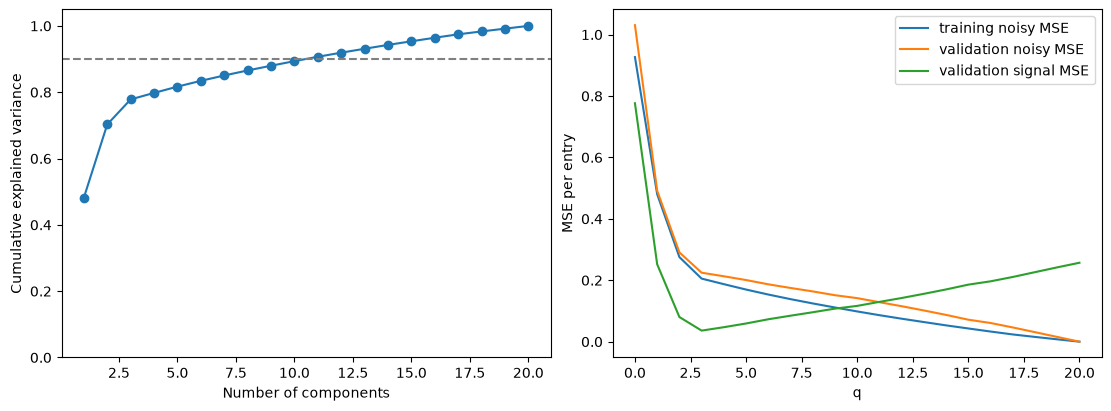

In [3]:
def reconstruct(inputs, q):
    directions = pca.components_[:q]
    scores = (inputs - pca.mean_) @ directions.T
    return pca.mean_ + scores @ directions

rows = []
for q in range(p+1):
    train_reconstruction = reconstruct(X_train, q)
    valid_reconstruction = reconstruct(X_valid, q)
    residual_sum = np.sum((X_train-train_reconstruction)**2)
    expected_sum = (len(X_train)-1) * pca.explained_variance_[q:].sum()
    np.testing.assert_allclose(residual_sum, expected_sum, atol=1e-9)
    rows.append({"q": q, "training noisy MSE": np.mean((X_train-train_reconstruction)**2),
                 "validation noisy MSE": np.mean((X_valid-valid_reconstruction)**2),
                 "validation signal MSE": np.mean((clean[valid_ids]-valid_reconstruction)**2)})
errors = pd.DataFrame(rows)
assert np.all(np.diff(errors["validation noisy MSE"]) <= 1e-12)
np.testing.assert_allclose(reconstruct(X_valid, p), X_valid, atol=1e-12)
cpve = np.cumsum(pca.explained_variance_ratio_)
q_90 = int(np.searchsorted(cpve, .90) + 1)
q_oracle = int(errors.loc[errors["validation signal MSE"].idxmin(), "q"])
print("Frozen q policies: design=3; 90% variance=", q_90, "; clean-validation oracle=", q_oracle)
display(errors.loc[errors["q"].isin([0, 3, q_90, q_oracle, p])])
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].plot(range(1, p+1), cpve, "o-")
axes[0].axhline(.9, color="gray", linestyle="--")
axes[0].set(xlabel="Number of components", ylabel="Cumulative explained variance", ylim=(0, 1.05))
for column in errors.columns[1:]:
    axes[1].plot(errors["q"], errors[column], label=column)
axes[1].set(xlabel="q", ylabel="MSE per entry")
axes[1].legend()
plt.show()

## 4. Evaluate frozen policies and storage

Compare q=3 (known signal dimension), the smallest training q with CPVE≥90%, and minimum clean-validation MSE.
The last is an oracle requiring clean targets. Include mean-only and full-reconstruction baselines;
none is selected from test.

`norm(P-P_true,"fro")` compares rank-three projection matrices without sign/rotation ambiguity.
Storing m rows requires $mq+pq+p$ numbers (scores, basis, mean) versus $mp$ originals;
this counts entries, not compressed-file bytes.

,policy,q,test noisy MSE,test signal MSE
0,Mean only,0,9.985554e-01,0.760701
1,Known signal dimension,3,2.244236e-01,0.038227
2,90% fitting variance,11,1.181933e-01,0.143124
3,Clean-validation oracle,3,2.244236e-01,0.038227
4,Full reconstruction,20,7.115637e-31,0.259112


Rank-three projection error (Frobenius norm): 0.15196918918605073
Observed-noise test MSE: 0.2591123052963154
Original entries for 600 rows: 12000
Stored entries with q=3, including mean and basis: 1880


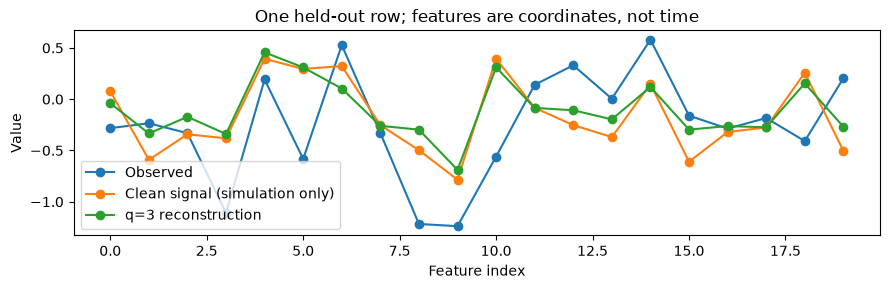

In [4]:
policies = [("Mean only", 0), ("Known signal dimension", 3), ("90% fitting variance", q_90),
            ("Clean-validation oracle", q_oracle), ("Full reconstruction", p)]
test_rows = []
for name, q in policies:
    reconstructed = reconstruct(X_test, q)
    test_rows.append({"policy": name, "q": q, "test noisy MSE": np.mean((X_test-reconstructed)**2),
                      "test signal MSE": np.mean((clean[test_ids]-reconstructed)**2)})
test_results = pd.DataFrame(test_rows)
display(test_results)
learned_projection = pca.components_[:3].T @ pca.components_[:3]
print("Rank-three projection error (Frobenius norm):", np.linalg.norm(learned_projection-B @ B.T, "fro"))
print("Observed-noise test MSE:", np.mean((X_test-clean[test_ids])**2))
print("Original entries for 600 rows:", n*p)
print("Stored entries with q=3, including mean and basis:", n*3+p*3+p)
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(range(p), X_test[0], "o-", label="Observed")
ax.plot(range(p), clean[test_ids[0]], "o-", label="Clean signal (simulation only)")
ax.plot(range(p), reconstruct(X_test[:1], 3)[0], "o-", label="q=3 reconstruction")
ax.set(xlabel="Feature index", ylabel="Value", title="One held-out row; features are coordinates, not time")
ax.legend(); plt.tight_layout(); plt.show()

## 5. Change feature units

Multiply feature 1 by 100: unscaled PCA now minimizes a different squared error.
Fit both scalers/PCAs on training rows only. `StandardScaler` uses variance divisor n;
PCA's `explained_variance_` uses n−1. Standardization cancels positive unit changes.

Check standardized full-basis variance ratios and three-component projection matrices.
These diagnostics do not replace unscaled policies; invariance does not establish that scaling suits this isotropic-noise model.

In [5]:
unit_change = np.ones(p)
unit_change[0] = 100
changed_pca = PCA(svd_solver="full").fit(X_train*unit_change)
scaler_original = StandardScaler().fit(X_train)
scaler_changed = StandardScaler().fit(X_train*unit_change)
Z_original = scaler_original.transform(X_train)
Z_changed = scaler_changed.transform(X_train*unit_change)
np.testing.assert_allclose(Z_original, Z_changed, atol=1e-12)
standardized_original = PCA(svd_solver="full").fit(Z_original)
standardized_changed = PCA(svd_solver="full").fit(Z_changed)
np.testing.assert_allclose(standardized_original.explained_variance_ratio_,
                           standardized_changed.explained_variance_ratio_, atol=1e-12)
V_original = standardized_original.components_[:3]
V_changed = standardized_changed.components_[:3]
np.testing.assert_allclose(V_original.T @ V_original, V_changed.T @ V_changed, atol=1e-12)
print("First PVE before/after raw unit change:", pca.explained_variance_ratio_[0], changed_pca.explained_variance_ratio_[0])
print("First PVE before/after standardized unit change:", standardized_original.explained_variance_ratio_[0],
      standardized_changed.explained_variance_ratio_[0])

First PVE before/after raw unit change: 0.4817728675502859 0.9986304304904259
First PVE before/after standardized unit change: 0.37099662163391955 0.3709966216339193


## Interpretation and documentation

Why does zero error to noisy observations not establish perfect denoising? Which selection policy could be used without
clean targets? Why compare projection matrices instead of individual signed eigenvectors? What information is lost in a two-PC plot?

The official [PCA documentation](https://scikit-learn.org/1.8/modules/generated/sklearn.decomposition.PCA.html)
explains `.components_`, variance attributes, solvers, and whitening. The
[StandardScaler documentation](https://scikit-learn.org/1.8/modules/generated/sklearn.preprocessing.StandardScaler.html)
specifies its variance convention. Keep `whiten=False` (the default) for the projection formulas here.
Never call `.fit` on validation or test rows when evaluating a frozen representation.